In [2]:
words=open('names.txt','r').read().splitlines()

In [3]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [4]:
b={}
for w in words:
  chs=['<S>']+list(w)+['<E>']
  for ch1, ch2 in zip(chs,chs[1:]):
    biagram=(ch1,ch2)
    b[biagram]=b.get(biagram,0)+1

In [5]:
sorted(b.items(), key=lambda kv: -kv[-1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [6]:
import torch

In [7]:
N=torch.zeros((27,27),dtype=torch.int32)

In [8]:
chars = sorted(list(set(''.join(words)) ))
#stoi = {s:i  for i,s in enumerate(chars)}
stoi={s:i+1 for i,s in enumerate(chars)}
#stoi['<S>'] = 26
#stoi['<E>'] = 27
stoi['.'] = 0
itos={i:s for s,i in stoi.items()}

In [9]:
for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    N[ix1,ix2]+=1

In [10]:
itos={i:s for s,i in stoi.items()}

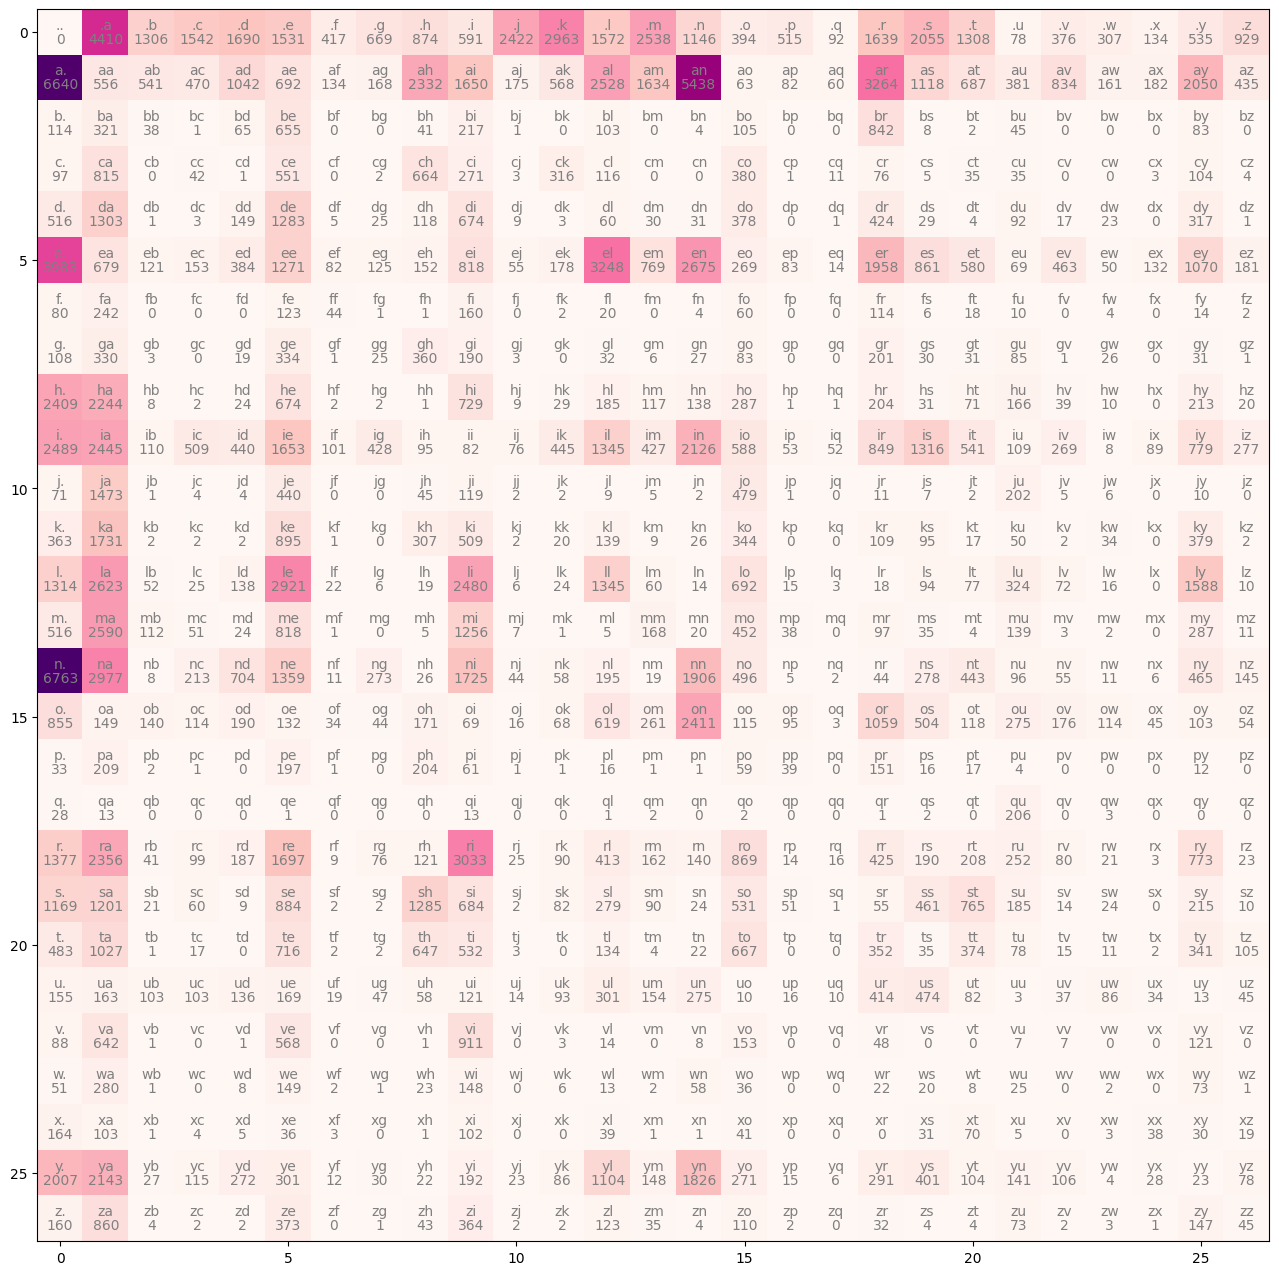

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N,cmap='RdPu')
for i in range (27):
  for j in range (27):
    chstr=itos[i]+itos[j]
    plt.text(j,i,chstr,ha='center',va='bottom',color='gray')
    plt.text(j,i,N[i,j].item(),ha='center',va='top',color='gray')

In [23]:
p= N[0].float()
p=p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [13]:
g=torch.Generator().manual_seed(2147483647)
p=torch.rand(3,generator=g)
p=p/p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [14]:
torch.multinomial(p,num_samples=50,replacement=True,generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2])

In [24]:
g=torch.Generator().manual_seed(2147483647)
ix=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
itos[ix]

'c'

In [25]:
ix

3

karpathy took m and ix 13. it results from how pytorch version difference is realted to manual_seed number

In [18]:
P=(N+1).float()
P/=P.sum(1,keepdim=True)

In [26]:
g=torch.Generator().manual_seed(2147483647)

for i in range(10):
  out=[]
  ix=0
  while True:
    #p=N[ix].float()
    #p=p/p.sum()
    p=P[ix]
    #p=torch.ones(27)/27.0
    ix=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


Two dimensions are compatible if they're equal, or one of them is 1 (the 1 gets stretched)

In [20]:
log_likelihood=0.0
n=0

for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    prob= P[ix1,ix2]
    logprob=torch.log(prob)
    log_likelihood+=logprob
    n+=1
    #print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll= -log_likelihood
print(f'{nll=}')
print(f'{nll/n:.4f}')

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4544


In [21]:
xs,ys =[],[]

for w in words[:1]:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    print(ch1,ch2)
    xs.append(ix1)
    ys.append(ix2)

xs=torch.tensor(xs)
ys=torch.tensor(ys)

. e
e m
m m
m a
a .


In [22]:
import torch.nn.functional as F
xenc= F.one_hot(xs, num_classes=27).float()
xenc


tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [27]:
xs

tensor([ 0,  5, 13, 13,  1])

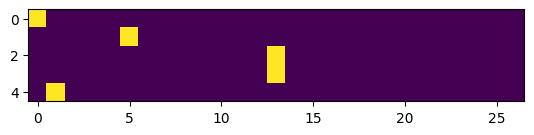

In [28]:
plt.imshow(xenc)

In [29]:
xenc.dtype

torch.float32

In [30]:
W=torch.randn((27,27))

In [31]:
(xenc@W).exp()

tensor([[0.8491, 0.6368, 0.2088, 3.2541, 0.4501, 1.6505, 1.7744, 0.6435, 3.2873,
         0.1510, 0.4678, 0.4407, 0.2450, 0.5783, 3.6338, 1.7122, 0.5632, 1.8694,
         2.6110, 1.9383, 0.6003, 0.3724, 2.0741, 0.2835, 0.2087, 0.5259, 0.4880],
        [3.3303, 2.2965, 0.1911, 1.3366, 0.3547, 1.0937, 0.1984, 0.6989, 2.3012,
         2.7425, 6.9369, 3.2205, 0.5214, 4.5349, 0.9535, 3.7542, 0.1337, 1.5304,
         4.5113, 2.3838, 0.6378, 0.5363, 3.2269, 1.6063, 2.6216, 1.7136, 0.4592],
        [3.2672, 1.4271, 3.2741, 0.4466, 0.2782, 0.7416, 0.3794, 0.9798, 0.3202,
         4.5743, 0.6356, 1.2457, 0.0875, 1.4442, 1.3211, 0.9121, 2.6481, 2.8229,
         1.3679, 1.6980, 1.3075, 2.8046, 1.9098, 0.9678, 0.4470, 1.4422, 1.2495],
        [3.2672, 1.4271, 3.2741, 0.4466, 0.2782, 0.7416, 0.3794, 0.9798, 0.3202,
         4.5743, 0.6356, 1.2457, 0.0875, 1.4442, 1.3211, 0.9121, 2.6481, 2.8229,
         1.3679, 1.6980, 1.3075, 2.8046, 1.9098, 0.9678, 0.4470, 1.4422, 1.2495],
        [0.6303, 0.1040,

In [32]:
logits=xenc@W
counts=logits.exp()
probs=counts/counts.sum(1,keepdims=True)
probs

tensor([[0.0269, 0.0202, 0.0066, 0.1032, 0.0143, 0.0524, 0.0563, 0.0204, 0.1043,
         0.0048, 0.0148, 0.0140, 0.0078, 0.0183, 0.1153, 0.0543, 0.0179, 0.0593,
         0.0828, 0.0615, 0.0190, 0.0118, 0.0658, 0.0090, 0.0066, 0.0167, 0.0155],
        [0.0619, 0.0427, 0.0036, 0.0248, 0.0066, 0.0203, 0.0037, 0.0130, 0.0428,
         0.0510, 0.1289, 0.0598, 0.0097, 0.0843, 0.0177, 0.0697, 0.0025, 0.0284,
         0.0838, 0.0443, 0.0118, 0.0100, 0.0600, 0.0298, 0.0487, 0.0318, 0.0085],
        [0.0817, 0.0357, 0.0819, 0.0112, 0.0070, 0.0185, 0.0095, 0.0245, 0.0080,
         0.1144, 0.0159, 0.0311, 0.0022, 0.0361, 0.0330, 0.0228, 0.0662, 0.0706,
         0.0342, 0.0425, 0.0327, 0.0701, 0.0477, 0.0242, 0.0112, 0.0361, 0.0312],
        [0.0817, 0.0357, 0.0819, 0.0112, 0.0070, 0.0185, 0.0095, 0.0245, 0.0080,
         0.1144, 0.0159, 0.0311, 0.0022, 0.0361, 0.0330, 0.0228, 0.0662, 0.0706,
         0.0342, 0.0425, 0.0327, 0.0701, 0.0477, 0.0242, 0.0112, 0.0361, 0.0312],
        [0.0213, 0.0035,

In [33]:
g=torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27),generator=g, requires_grad=True) #randn normal distribution

In [34]:
probs[0,5], probs[1,13], probs[2,13], probs [3,1], probs[4,0]

(tensor(0.0524),
 tensor(0.0843),
 tensor(0.0361),
 tensor(0.0357),
 tensor(0.0213))

In [35]:
torch.arange(5)

tensor([0, 1, 2, 3, 4])

In [36]:
loss=-probs[torch.arange(5),ys].log().mean()
loss

tensor(3.1855)

In [37]:
#forward pass
xenc= F.one_hot(xs, num_classes=27).float() #one hot encoding
logits=xenc@W
counts=logits.exp() #==N
probs=counts/counts.sum(1,keepdims=True) #softmax
loss=-probs[torch.arange(5),ys].log().mean()

In [38]:
print(loss.item())

3.7693049907684326


In [39]:
#backward
W.grad=None
loss.backward()

In [40]:
W.data += -0.1*W.grad

Actual gradient descent and optimization part

In [41]:
xs, ys =[],[]
for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs=torch.tensor(xs)
ys=torch.tensor(ys)
num= xs.nelement()
print("Number of examples: ",num)

g=torch.Generator().manual_seed(2147483647)
W=torch.randn((27,27),generator=g,requires_grad=True)

Number of examples:  228146


The first term (the data loss) says: "make good predictions — assign high probability to the correct next character." The second term says: "and keep the weights small while you're at it." Training tries to minimize the sum, so it has to balance both.prevent overfitting

In [42]:
#gradient descent
for k in range(100):
  #forward pass
  xenc= F.one_hot(xs, num_classes=27).float() #one hot encoding
  logits=xenc@W
  counts=logits.exp() #==N
  probs=counts/counts.sum(1,keepdims=True) #softmax
  loss=-probs[torch.arange(num),ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())

  #backward pass
  W.grad=None
  loss.backward()

  #update
  W.data += -50*W.grad

3.7686190605163574
3.3788068294525146
3.161090850830078
3.0271859169006348
2.9344842433929443
2.867231607437134
2.8166539669036865
2.777146339416504
2.745253801345825
2.7188303470611572
2.696505308151245
2.6773722171783447
2.6608052253723145
2.6463513374328613
2.633665084838867
2.622471570968628
2.6125476360321045
2.6037065982818604
2.595794916152954
2.5886809825897217
2.5822560787200928
2.5764293670654297
2.5711236000061035
2.566272735595703
2.5618226528167725
2.5577263832092285
2.5539438724517822
2.550442695617676
2.5471925735473633
2.5441696643829346
2.5413525104522705
2.538721799850464
2.536262273788452
2.5339579582214355
2.531797409057617
2.5297679901123047
2.527860164642334
2.5260636806488037
2.5243709087371826
2.522773265838623
2.52126407623291
2.519836664199829
2.5184857845306396
2.5172057151794434
2.515990734100342
2.5148372650146484
2.5137407779693604
2.512697696685791
2.511704921722412
2.5107579231262207
2.509854793548584
2.5089924335479736
2.5081682205200195
2.5073802471160

result for with coutning case was 2.4544, pretty close to gradient descent result


In [43]:
g= torch.Generator().manual_seed(2147483647)

for i in range (5):
  out=[]
  ix=0
  while True:
    #p=P[ix]

    xenc=F.one_hot(torch.tensor([ix]),num_classes=27).float()
    logits=xenc@W
    counts=logits.exp()
    p=counts/counts.sum(1,keepdims=True)

    ix=torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.


after case: cexze.
momasurailezityha.
konimittain.
llayn.
ka.

before case : cexze.
momasurailezitynn.
konimittain.
llayn.
ka.

---------------------Turkish names----------

In [44]:
words = open('turkish_names.txt', 'r', encoding='utf-8').read().splitlines()

chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0                                  # '.' is the start/end token = 0
itos = {i: s for s, i in stoi.items()}        # reverse map

vocab_size = len(itos)
print(vocab_size)

30


In [45]:
min(len(w) for w in words), max(len(w) for w in words)

(2, 17)

In [46]:
for w in words:
    if len(w) == 17:
        print(w)

altıntamgantarkan
bilgeışbaratamgan
biligköngülsengün


In [66]:
N = torch.zeros((vocab_size, vocab_size), dtype=torch.int32)   # was (27, 27)

for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

# probabilities with smoothing
P = (N + 1).float()
P = P / P.sum(1, keepdim=True)

In [67]:
log_likelihood=0.0
n=0

for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    prob= P[ix1,ix2]
    logprob=torch.log(prob)
    log_likelihood+=logprob
    n+=1
    #print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll= -log_likelihood
print(f'{nll=}')
print(f'{nll/n:.4f}')

log_likelihood=tensor(-56211.1445)
nll=tensor(56211.1445)
2.4544


In [68]:
g=torch.Generator().manual_seed(2147483647)

for i in range(10):
  out=[]
  ix=0
  while True:
    #p=N[ix].float()
    #p=p/p.sum()
    p=P[ix]
    #p=torch.ones(27)/27.0
    ix=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

unsrançmokslbör.
e.
çerdış.
tmur.
baçulgüze.
tu.
çimengiyşbersa.
h.
at.
ürsayeç.


In [49]:
import torch.nn.functional as F

# build the training set of bigrams
xs, ys = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs.append(stoi[ch1])
        ys.append(stoi[ch2])
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()

g = torch.Generator().manual_seed(2147483647)
W = torch.randn((vocab_size, vocab_size), generator=g, requires_grad=True)


4.0134100914001465
3.6078014373779297
3.344144582748413
3.17214298248291
3.0569024085998535
2.972651720046997
2.9078478813171387
2.8564982414245605
2.8148157596588135
2.780259370803833
2.751107692718506
2.7261743545532227
2.70462703704834
2.6858632564544678
2.66943359375
2.6549859046936035
2.642238140106201
2.6309521198272705
2.6209285259246826
2.6119930744171143
2.6039962768554688
2.596809148788452
2.590320348739624
2.5844361782073975
2.579076051712036
2.574172258377075
2.5696685314178467
2.565516233444214
2.5616767406463623
2.558114767074585
2.554802417755127
2.551713705062866
2.548828125
2.546126365661621
2.5435924530029297
2.5412113666534424
2.538970708847046
2.536858320236206
2.5348639488220215
2.5329782962799072
2.5311925411224365
2.5294995307922363
2.5278918743133545
2.5263631343841553
2.5249080657958984
2.5235211849212646
2.522197723388672
2.5209336280822754
2.5197243690490723
2.5185670852661133
2.5174574851989746
2.5163938999176025
2.5153732299804688
2.5143918991088867
2.51344

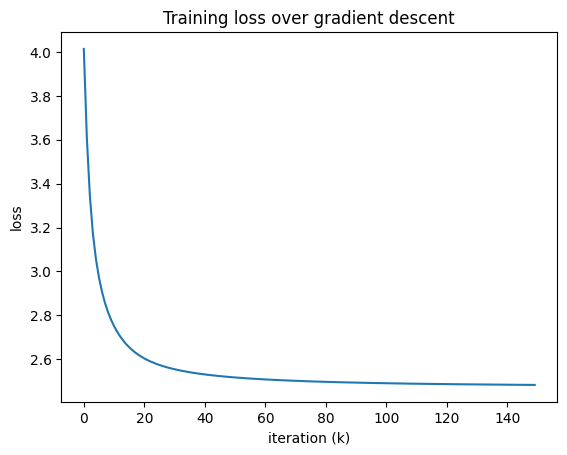

In [50]:
import matplotlib.pyplot as plt

losses=[]

#gradient descent
for k in range(150):
  #forward pass
  xenc= F.one_hot(xs, num_classes=vocab_size).float() #one hot encoding
  logits=xenc@W
  counts=logits.exp() #==N
  probs=counts/counts.sum(1,keepdims=True) #softmax
  loss=-probs[torch.arange(num),ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())
  losses.append(loss.item())
  #backward pass
  W.grad=None
  loss.backward()

  #update
  W.data += -50*W.grad

print(loss.item())

plt.plot(losses)
plt.xlabel('iteration (k)')
plt.ylabel('loss')
plt.title('Training loss over gradient descent')
plt.show()

In [51]:
g= torch.Generator().manual_seed(2147483647)

for i in range (30):
  out=[]
  ix=0
  while True:

    xenc=F.one_hot(torch.tensor([ix]),num_classes=vocab_size).float()
    logits=xenc@W
    counts=logits.exp()
    p=counts/counts.sum(1,keepdims=True)

    ix=torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

unsu.
çoğmuslbör.
e.
çerdışhtmur.
baçulgüze.
tuin.
a.
turışbersa.
h.
at.
ürsayeç.
azmüyuturan.
ekadumı.
kemay.
ekar.
jdur.
aydum.
u.
ıy.
akç.
ikar.
kaydürbayunakı.
er.
ben.
ökiltuğaniş.
ka.
elışenetaykok.
talulmay.
tom.
yü.


Trigram model part

In [75]:
#split data
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
train_words = words[:n1]     
dev_words = words[n1:n2]    
test_words = words[n2:]      

print(len(train_words), len(dev_words), len(test_words))

2476 309 310


In [ ]:
N3 = torch.zeros((30, 30, 30), dtype=torch.int32)

for w in train_words:
    chs = ['.', '.'] + list(w) + ['.']       # two dots at the start
    for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
        N3[stoi[ch1], stoi[ch2], stoi[ch3]] += 1

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
N_2d = N3.sum(dim=2)


plt.imshow(N_2d, cmap='RdPu')

for i in range(vocab_size):
    for j in range(vocab_size):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, N_2d[i, j].item(), ha='center', va='top', color='gray')

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
N_2d = N3.sum(dim=2)


Nviz = N_2d.clone()
Nviz[0, 0] = 0

plt.imshow(Nviz, cmap='RdPu')

for i in range(vocab_size):
    for j in range(vocab_size):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha='center', va='bottom', color='gray')
        plt.text(j, i, Nviz[i, j].item(), ha='center', va='top', color='gray')

In [ ]:
def trigram_loss(word_list, k):
    P = (N3 + k).float()
    P = P / P.sum(2, keepdim=True)       # normalize over the "next letter" axis, for binomil it was 1 becuase we were considering only the previous letter, now we are considering the previous two letters
    log_likelihood = 0.0
    n = 0
    for w in word_list:
        chs = ['.', '.'] + list(w) + ['.']
        for ch1, ch2, ch3 in zip(chs, chs[1:], chs[2:]):
            p = P[stoi[ch1], stoi[ch2], stoi[ch3]]
            log_likelihood += torch.log(p)
            n += 1
    return -log_likelihood / n              #again negatiive log likelihood loss 

In [ ]:
N2 = torch.zeros((30, 30), dtype=torch.int32)

for w in train_words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        N2[stoi[ch1], stoi[ch2]] += 1

In [ ]:
def bigram_loss(word_list, k):
    P = (N2 + k).float()
    P = P / P.sum(1, keepdim=True)       
    log_likelihood = 0.0
    n = 0
    for w in word_list:
        chs = ['.'] + list(w) + ['.']
        for ch1, ch2 in zip(chs, chs[1:]):
            ix1 = stoi[ch1]
            ix2 = stoi[ch2]
            prob = P[ix1, ix2]
            log_likelihood += torch.log(prob)
            n += 1
    return -log_likelihood / n          

In [81]:
for k in [0.01, 0.1, 0.3, 1, 3, 10, 50, 100]:
    dev = trigram_loss(dev_words, k)
    print(f"k={k:<6}  dev loss = {dev:.4f}") #tune smoothing parameter k to minimize dev loss -- best one is k=0.1 dev loss = 2.2049

k=0.01    dev loss = 2.4195
k=0.1     dev loss = 2.3028
k=0.3     dev loss = 2.3054
k=1       dev loss = 2.3931
k=3       dev loss = 2.5642
k=10      dev loss = 2.8159
k=50      dev loss = 3.1221
k=100     dev loss = 3.2154


In [82]:
for k in [0.005, 0.01, 0.1, 0.3, 1, 3, 10, 50, 100]:
    dev = bigram_loss(dev_words, k)
    print(f"k={k:<6}  dev loss = {dev:.4f}") #tune smoothing parameter k to minimize dev loss -- best one is k=0.01    dev loss = 2.4465

TypeError: unsupported format string passed to Tensor.__format__

In [ ]:
print("Trigram test loss:", trigram_loss(test_words, 0.1))
print("Bigram test loss:", bigram_loss(test_words, 0.01))

IndexError: Dimension out of range (expected to be in range of [-2, 1], but got 2)